In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm
import os
import warnings

# Anchor exactly to your local data folder relative to the notebook
DATA_DIR = Path("../data").resolve()
TRAIN_DIR = DATA_DIR / "train" / "train"
TEST_DIR = DATA_DIR / "test" / "test"
TRAIN_CSV = DATA_DIR / "train.csv"

print(f"Local Data Directory: {DATA_DIR}")

# Verify directory existence
assert DATA_DIR.exists(), f"CRITICAL: Data directory not found at {DATA_DIR}"
assert TRAIN_DIR.exists(), f"CRITICAL: Train directory not found at {TRAIN_DIR}"
print("SUCCESS: Local dataset located.")

Local Data Directory: D:\Semester 5\SD4504_SML\Document-Image-Classification\data
SUCCESS: Local dataset located.


Total rows in raw train.csv: 32003


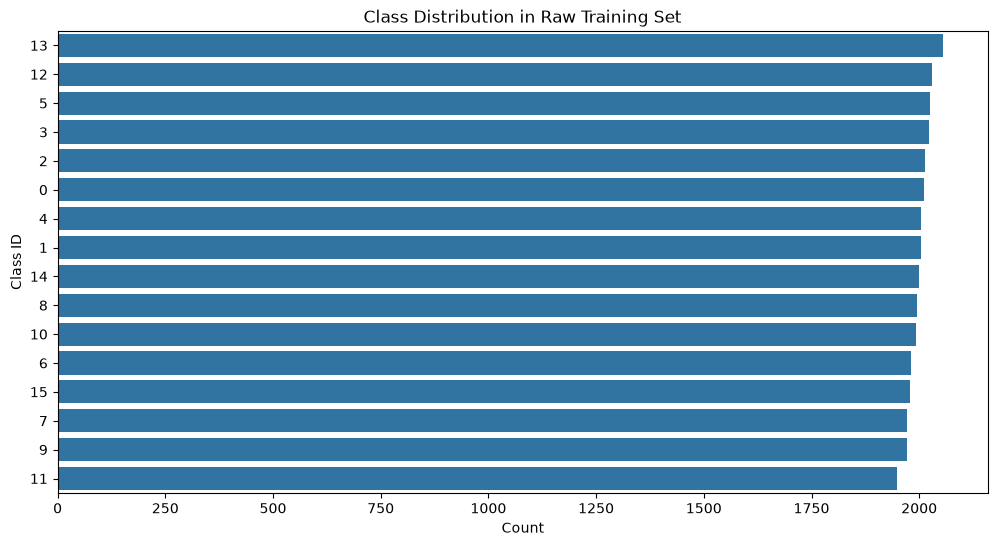

In [15]:
# Load the raw dataset
train_df = pd.read_csv(TRAIN_CSV)
print(f"Total rows in raw train.csv: {len(train_df)}")

# Visualize class imbalance
plt.figure(figsize=(12, 6))
sns.countplot(data=train_df, y='label', order=train_df['label'].value_counts().index)
plt.title("Class Distribution in Raw Training Set")
plt.xlabel("Count")
plt.ylabel("Class ID")
plt.show()

In [16]:
# Suppress harmless EXIF warnings so we only see actual hard errors
warnings.filterwarnings("ignore", "(?s).*Corrupt EXIF data.*")

image_paths = list(TRAIN_DIR.rglob("*.tif"))
print(f"Total .tif files found on disk: {len(image_paths)}")

def process_image(img_path):
    """Loads image to check for hard corruption and extracts metadata simultaneously."""
    try:
        with Image.open(img_path) as img:
            img.load()  # Forces PIL to read the file, catching deep corruptions
            return {
                "filename": img_path.name,
                "width": img.width,
                "height": img.height,
                "mode": img.mode,
                "aspect_ratio": img.width / img.height,
                "is_valid": True
            }
    except Exception as e:
        return {"filename": img_path.name, "is_valid": False, "error": str(e)}

# Multi-threaded sweep across all 32,003 images
with ThreadPoolExecutor(max_workers=8) as executor:
    results = list(tqdm(executor.map(process_image, image_paths), total=len(image_paths)))

# Separate valid metadata from corrupted files
meta_df = pd.DataFrame([r for r in results if r["is_valid"]])
corrupted_files = [r["filename"] for r in results if not r["is_valid"]]

print(f"\nScan complete. Total corrupted files found: {len(corrupted_files)}")

Total .tif files found on disk: 32003


100%|██████████| 32003/32003 [00:42<00:00, 759.43it/s]


Scan complete. Total corrupted files found: 1


In [17]:
if len(corrupted_files) > 0:
    print(f"Corrupted filenames: {corrupted_files[:5]}...")
    
    # Filter out the bad rows based on the exact filename string at the end of the path
    clean_df = train_df[~train_df['filename'].apply(lambda x: Path(x).name).isin(corrupted_files)]
    
    # Define the backup path
    old_csv_path = DATA_DIR / "train_old.csv"
    
    # Safely rename the original train.csv to train_old.csv
    if TRAIN_CSV.exists():
        if old_csv_path.exists():
            old_csv_path.unlink()  # Remove existing backup if you run this cell twice
        TRAIN_CSV.rename(old_csv_path)
    
    # Save the sanitized CSV exactly as the original name
    clean_df.to_csv(TRAIN_CSV, index=False)
    
    print(f"Original CSV safely backed up to: {old_csv_path.name}")
    print(f"Sanitized CSV saved as: {TRAIN_CSV.name}")
    print(f"Rows dropped: {len(train_df) - len(clean_df)}")
else:
    print("Dataset is perfectly clean! No files were modified.")

Corrupted filenames: ['2500126531_2500126536.tif']...
Original CSV safely backed up to: train_old.csv
Sanitized CSV saved as: train.csv
Rows dropped: 1
